# Lab 06 — Image Segmentation: Point, Line, Edge Detection, Hough Transform and Thresholding

**Name:** __M.Talha Ramzan **Reg. No.:** ___2330-0141
## Lab Outcomes
- Explain image segmentation and intensity discontinuities.
- Use intensity differences to highlight abrupt changes.
- Detect points, directional lines, and edges using spatial operators.
- Compare first- and second-derivative responses near a noisy edge.
- Compute gradient magnitude and orientation.
- Apply the Canny edge detector and analyze its parameters.
- Detect line segments using the Hough transform.
- Compare global, Otsu, and adaptive thresholding.

## Background
Image segmentation partitions an image into meaningful regions. **Discontinuity-based** methods detect abrupt changes such as points, lines, and edges; **similarity-based** methods group pixels with similar properties, for example through thresholding.

First derivatives respond strongly to step edges. Second derivatives can produce positive/negative lobes and zero crossings near edges, but differentiation amplifies noise.

**Marks distribution:** ER1 (Task Completion) = 3, ER6 (Program Output) = 3, ER8 (Question & Answer) = 4.

## 1. Setup and Input Image

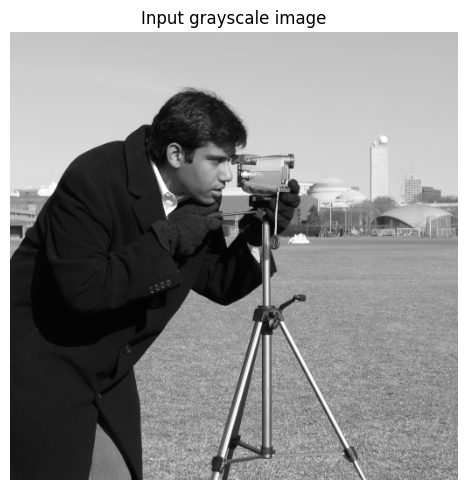

Shape: (512, 512) Range: 0 255


In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, img_as_ubyte

def show_images(images, titles, cmaps=None, figsize=None):
    if figsize is None: figsize = (4*len(images), 4)
    if cmaps is None: cmaps = ["gray"]*len(images)
    plt.figure(figsize=figsize)
    for i, (im, title, cmap) in enumerate(zip(images, titles, cmaps), 1):
        plt.subplot(1, len(images), i)
        plt.imshow(im, cmap=cmap); plt.title(title); plt.axis("off")
    plt.tight_layout(); plt.show()

gray = img_as_ubyte(data.camera())
show_images([gray], ["Input grayscale image"], figsize=(5,5))
print("Shape:", gray.shape, "Range:", gray.min(), gray.max())

## 2. Experiment 1 — Image Segmentation and Intensity Difference
Horizontal and vertical intensity differences approximate local changes. Large absolute differences can indicate edges, although textured regions may also generate strong responses.

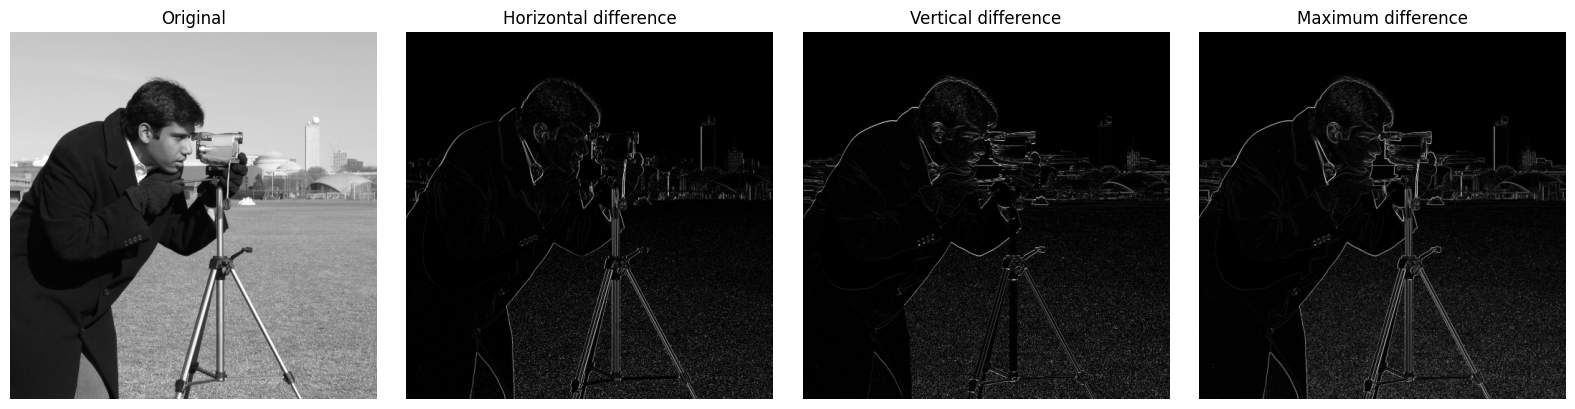

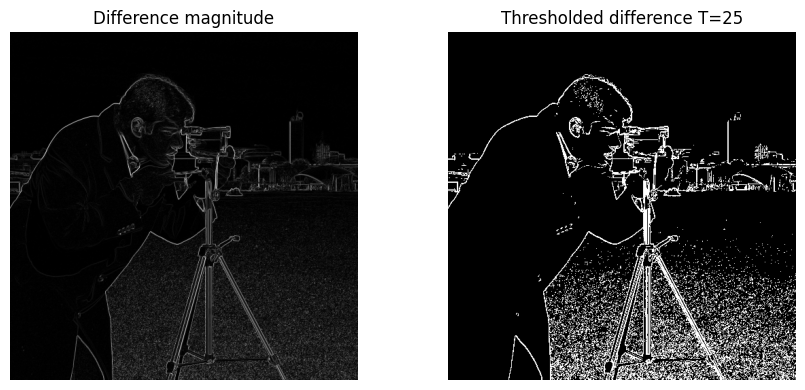

In [15]:
f = gray.astype(np.float32)
dx = np.abs(f[:,1:] - f[:,:-1]); dy = np.abs(f[1:,:] - f[:-1,:])
dx = np.pad(dx, ((0,0),(0,1)), mode="edge")
dy = np.pad(dy, ((0,1),(0,0)), mode="edge")
diff = np.maximum(dx, dy)
show_images([gray, dx, dy, diff],
            ["Original", "Horizontal difference", "Vertical difference", "Maximum difference"], figsize=(16,4))

T = 25
diff_mask = (diff > T).astype(np.uint8)*255
show_images([diff, diff_mask], ["Difference magnitude", f"Thresholded difference T={T}"], figsize=(9,4))

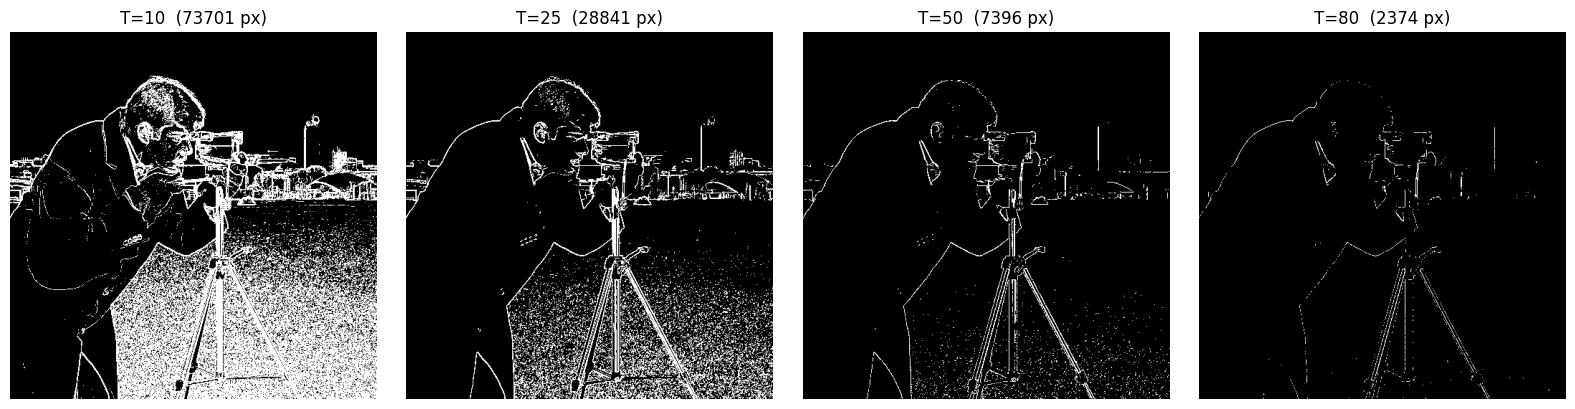

In [16]:
# Task: change T and observe the effect on the number of detected pixels
Ts = [10, 25, 50, 80]
masks = [(diff > t).astype(np.uint8)*255 for t in Ts]
show_images(masks, [f"T={t}  ({(m>0).sum()} px)" for t, m in zip(Ts, masks)], figsize=(16,4))

## 3. Experiment 2 — Point, Line and Edge Detection
### 3.1 Point detection
A point mask responds to a pixel that differs from its neighborhood. The threshold is image-dependent.

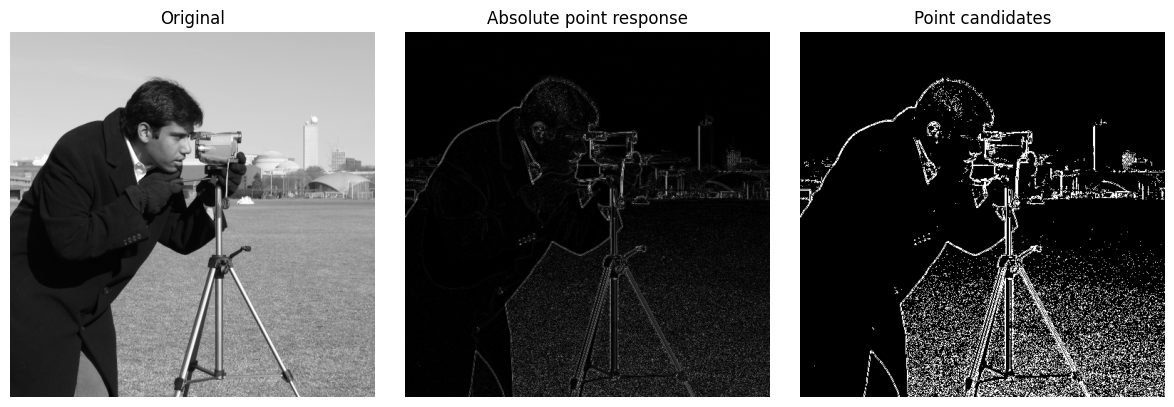

In [17]:
point_kernel = np.array([[-1,-1,-1],[-1,8,-1],[-1,-1,-1]], np.float32)
point_response = cv2.filter2D(gray.astype(np.float32), cv2.CV_32F, point_kernel)
point_mask = (np.abs(point_response) > 120).astype(np.uint8)*255
show_images([gray, np.abs(point_response), point_mask],
            ["Original", "Absolute point response", "Point candidates"], figsize=(12,4))

### 3.2 Directional line detection

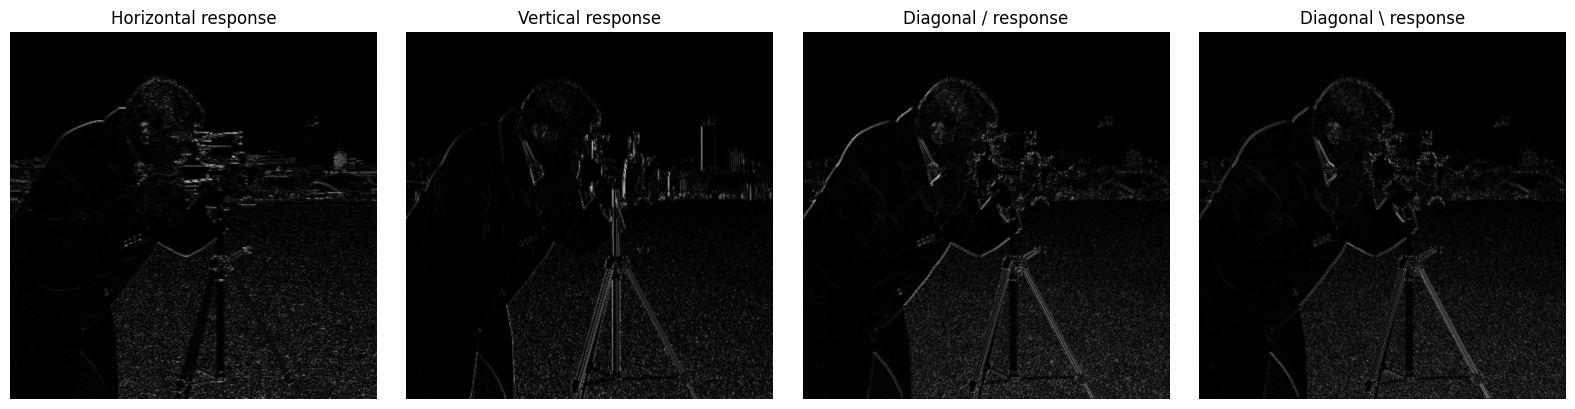

In [18]:
line_kernels = {
    "Horizontal": np.array([[-1,-1,-1],[ 2, 2, 2],[-1,-1,-1]], np.float32),
    "Vertical":   np.array([[-1, 2,-1],[-1, 2,-1],[-1, 2,-1]], np.float32),
    "Diagonal /": np.array([[-1,-1, 2],[-1, 2,-1],[ 2,-1,-1]], np.float32),   # 2s run bottom-left -> top-right
    "Diagonal \\": np.array([[ 2,-1,-1],[-1, 2,-1],[-1,-1, 2]], np.float32)}  # 2s run top-left -> bottom-right
responses = []; titles = []
for name, kernel in line_kernels.items():
    responses.append(np.abs(cv2.filter2D(gray.astype(np.float32), cv2.CV_32F, kernel)))
    titles.append(name + " response")
show_images(responses, titles, figsize=(16,4))

### 3.3 Sobel edge detection

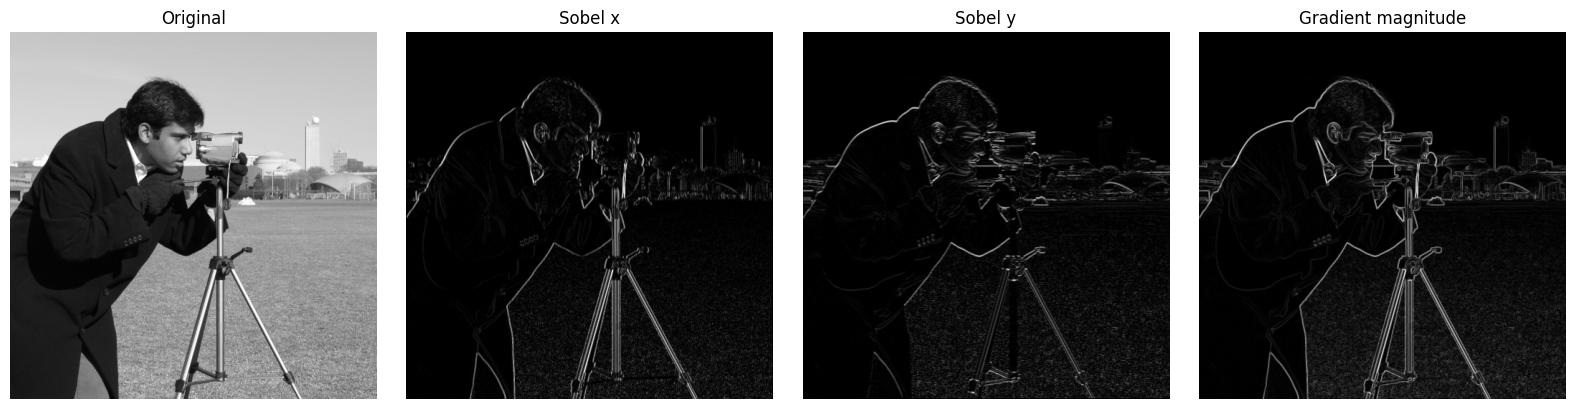

In [19]:
gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
mag = cv2.magnitude(gx, gy)
mag8 = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
show_images([gray, np.abs(gx), np.abs(gy), mag8],
            ["Original", "Sobel x", "Sobel y", "Gradient magnitude"], figsize=(16,4))

## 4. Experiment 3 — First and Second Derivatives near a Noisy Edge
A first derivative peaks near an intensity transition. A second derivative changes sign around the transition and may have a zero crossing near the edge. Noise creates spurious responses, particularly in second derivatives.

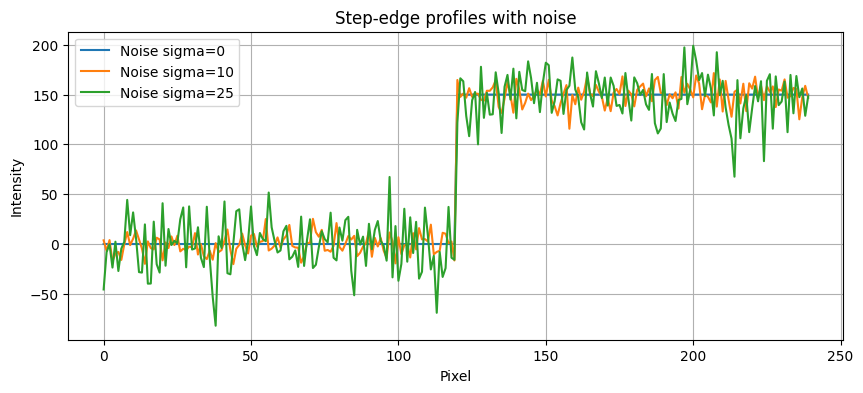

In [20]:
rng = np.random.default_rng(10)
profile = np.zeros(240, dtype=np.float32); profile[120:] = 150

plt.figure(figsize=(10,4))
for sigma in [0, 10, 25]:
    noisy = profile + rng.normal(0, sigma, profile.shape).astype(np.float32)
    plt.plot(noisy, label=f"Noise sigma={sigma}")
plt.title("Step-edge profiles with noise"); plt.xlabel("Pixel"); plt.ylabel("Intensity")
plt.legend(); plt.grid(True); plt.show()

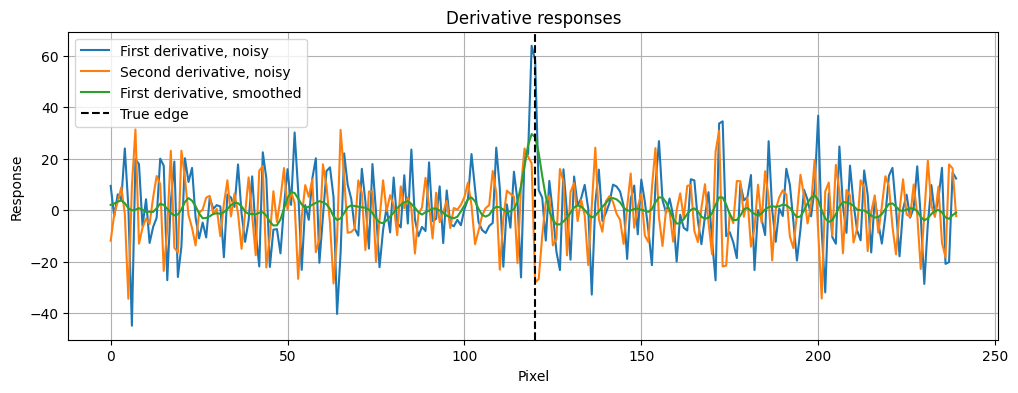

In [21]:
noisy = profile + rng.normal(0, 20, profile.shape).astype(np.float32)
first = np.gradient(noisy); second = np.gradient(first)

# NOTE: OpenCV ksize is (width, height). The profile is a 1 x N row, so use (9,1) to smooth ALONG the row.
smooth = cv2.GaussianBlur(noisy.reshape(1,-1), (9,1), 2).ravel()
first_s = np.gradient(smooth); second_s = np.gradient(first_s)

plt.figure(figsize=(12,4))
plt.plot(first, label="First derivative, noisy")
plt.plot(second, label="Second derivative, noisy")
plt.plot(first_s, label="First derivative, smoothed")
plt.axvline(120, linestyle="--", color="k", label="True edge")
plt.xlabel("Pixel"); plt.ylabel("Response"); plt.title("Derivative responses")
plt.legend(); plt.grid(True); plt.show()

## 5. Experiment 4 — Image Gradient
The gradient consists of horizontal and vertical derivatives. Magnitude estimates edge strength; orientation estimates the direction of maximum intensity increase.

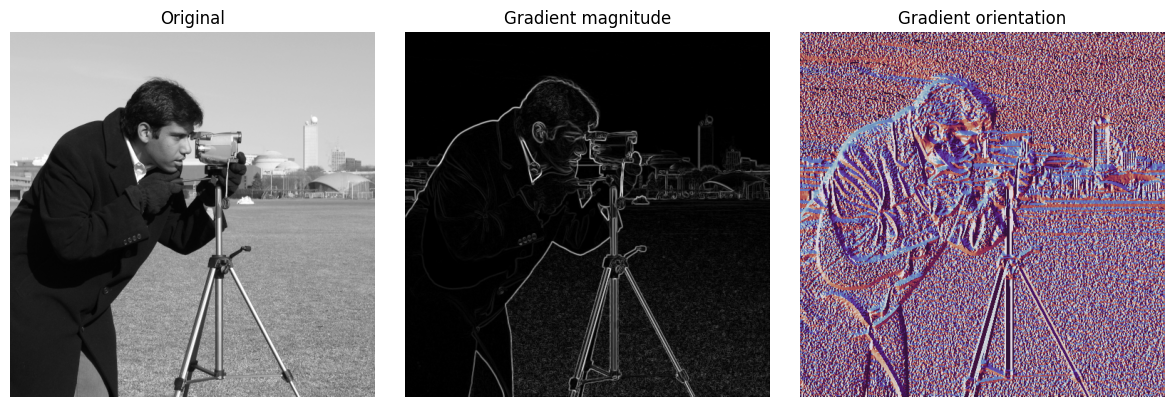

Orientation range: -3.1395885944366455 3.1415927410125732


In [22]:
gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
magnitude = np.sqrt(gx**2 + gy**2)
orientation = np.arctan2(gy, gx)
mag8 = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
show_images([gray, mag8, orientation], ["Original", "Gradient magnitude", "Gradient orientation"],
            cmaps=["gray","gray","twilight"], figsize=(12,4))
print("Orientation range:", float(orientation.min()), float(orientation.max()))

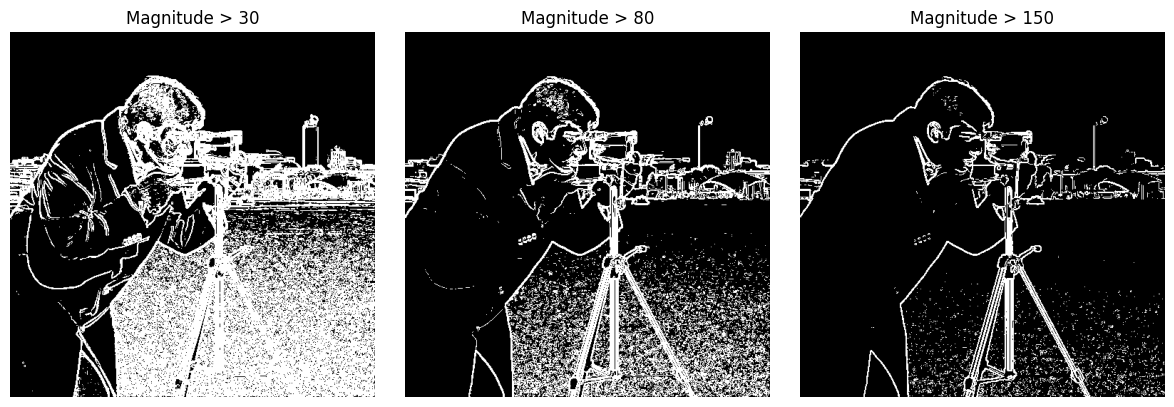

In [23]:
# Thresholding gradient magnitude -> binary edge map
edge_maps = [(magnitude > t).astype(np.uint8)*255 for t in [30, 80, 150]]
show_images(edge_maps, [f"Magnitude > {t}" for t in [30, 80, 150]], figsize=(12,4))

## 6. Experiment 5 — The Canny Edge Detector
Canny combines Gaussian smoothing, gradient estimation, non-maximum suppression, double thresholding, and edge tracking by hysteresis.

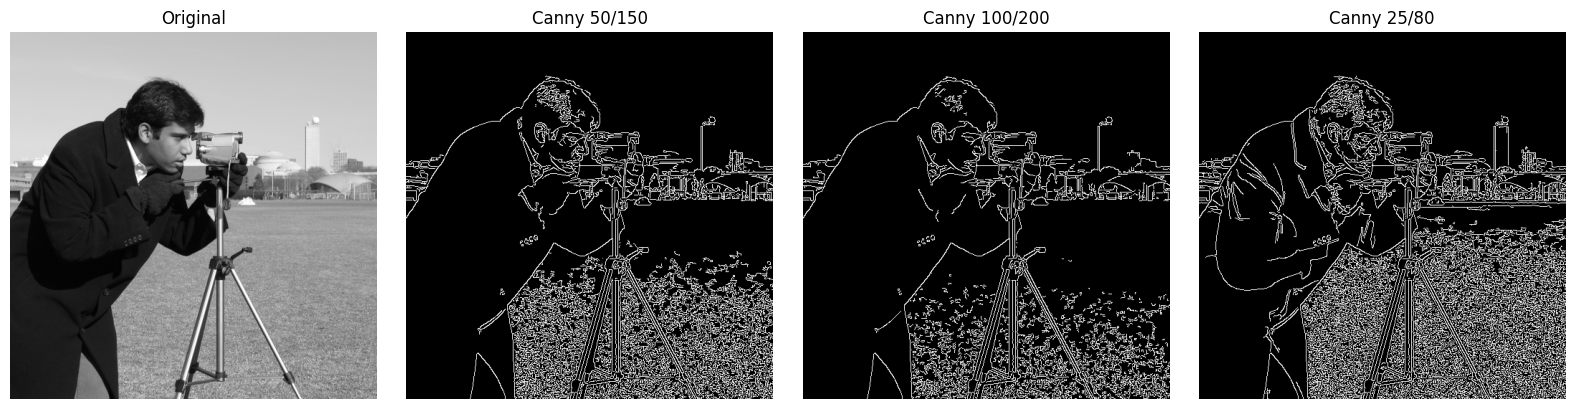

Edge pixels -> 50/150: 30980  100/200: 19686  25/80: 42613


In [24]:
c1 = cv2.Canny(gray, 50, 150)
c2 = cv2.Canny(gray, 100, 200)
c3 = cv2.Canny(gray, 25, 80)
show_images([gray, c1, c2, c3], ["Original", "Canny 50/150", "Canny 100/200", "Canny 25/80"], figsize=(16,4))
print("Edge pixels -> 50/150:", int((c1>0).sum()), " 100/200:", int((c2>0).sum()), " 25/80:", int((c3>0).sum()))

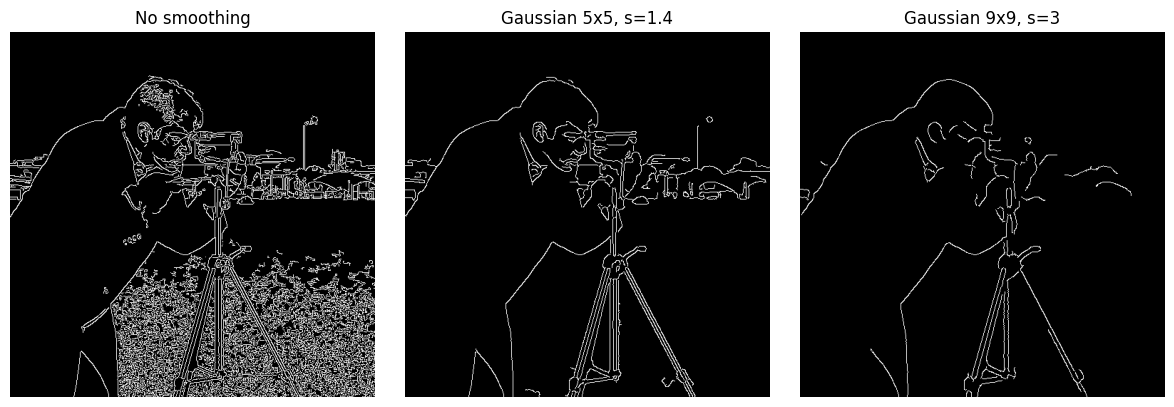

In [25]:
# Smoothing before Canny
blur = cv2.GaussianBlur(gray, (5,5), 1.4)
blur2 = cv2.GaussianBlur(gray, (9,9), 3)
show_images([cv2.Canny(gray,50,150), cv2.Canny(blur,50,150), cv2.Canny(blur2,50,150)],
            ["No smoothing", "Gaussian 5x5, s=1.4", "Gaussian 9x9, s=3"], figsize=(12,4))

## 7. Experiment 6 — Hough Transform
The Hough transform maps edge pixels into parameter space to find likely geometric lines. The probabilistic version returns line segments.

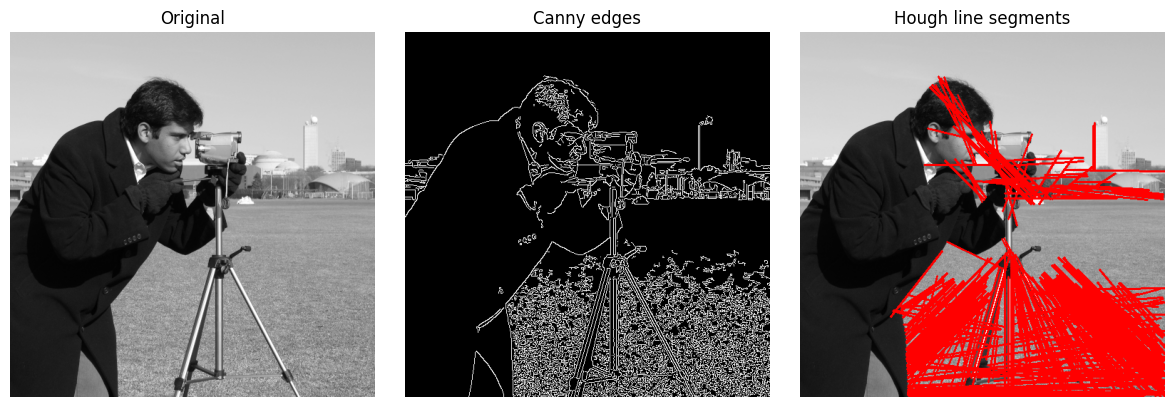

Detected segments: 282


In [27]:
edges = cv2.Canny(gray, 50, 150)
lines = cv2.HoughLinesP(edges, rho=1, theta=np.pi/180, threshold=80, minLineLength=50, maxLineGap=10)
overlay = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
if lines is not None:
    for item in lines:
        # item.ravel() safely flattens the coordinate array to [x1, y1, x2, y2]
        x1, y1, x2, y2 = item.ravel()
        cv2.line(overlay, (x1, y1), (x2, y2), (255, 0, 0), 2)
show_images([gray, edges, overlay], ["Original", "Canny edges", "Hough line segments"],
            cmaps=["gray","gray",None], figsize=(12,4))
print("Detected segments:", 0 if lines is None else len(lines))

threshold= 40 minLen= 30 maxGap=10 -> segments: 563
threshold= 80 minLen= 50 maxGap=10 -> segments: 282
threshold=150 minLen= 50 maxGap=10 -> segments: 35
threshold= 80 minLen=100 maxGap=10 -> segments: 143
threshold= 80 minLen= 50 maxGap=40 -> segments: 160


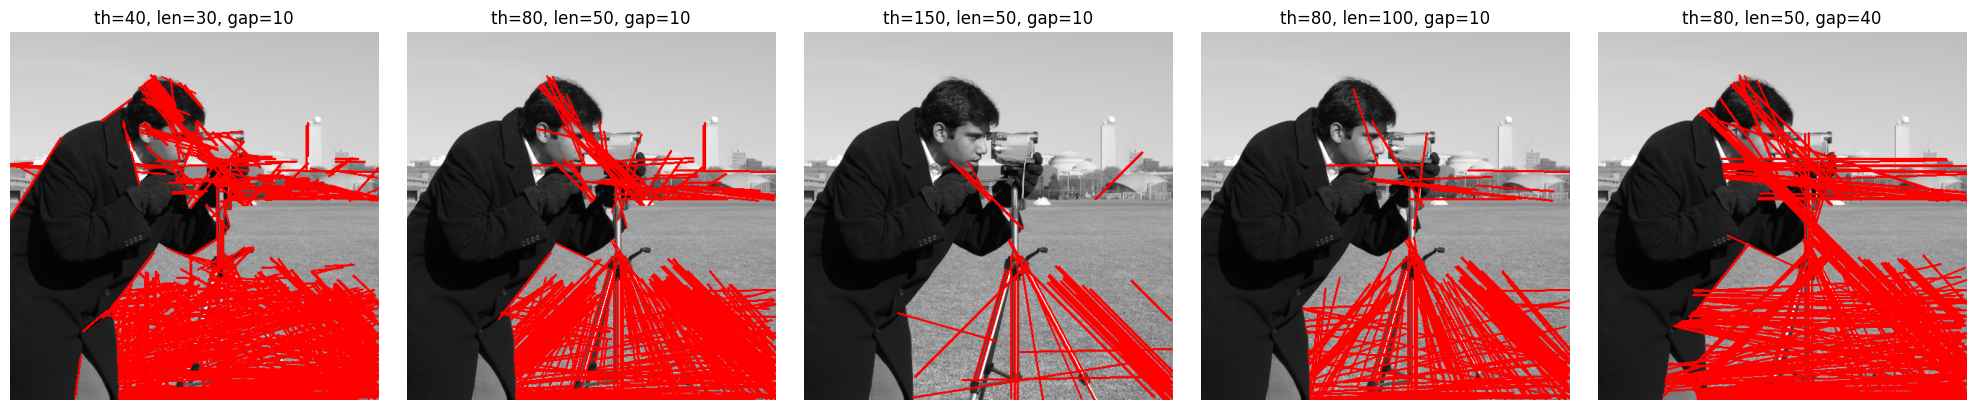

In [29]:
# Vary accumulator threshold, minLineLength and maxLineGap
settings = [(40,30,10), (80,50,10), (150,50,10), (80,100,10), (80,50,40)]
outs = []
for th, ml, mg in settings:
    L = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=th, minLineLength=ml, maxLineGap=mg)
    o = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    if L is not None:
        for it in L:
            x1, y1, x2, y2 = it.ravel()
            cv2.line(o, (x1, y1), (x2, y2), (255, 0, 0), 2)
    outs.append(o)
    print(f"threshold={th:3d} minLen={ml:3d} maxGap={mg:2d} -> segments: {0 if L is None else len(L)}")
show_images(outs, [f"th={s[0]}, len={s[1]}, gap={s[2]}" for s in settings],
            cmaps=[None]*len(outs), figsize=(20,4))

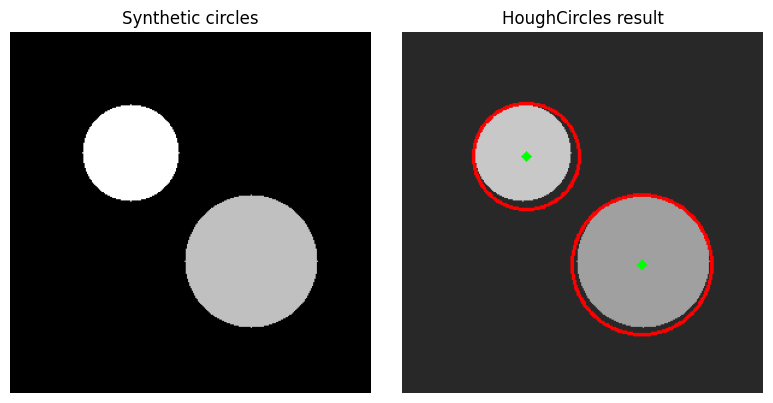

In [30]:
# Optional: Hough circles on a synthetic image
circ = np.full((300,300), 40, np.uint8)
cv2.circle(circ, (100,100), 40, 200, -1); cv2.circle(circ, (200,190), 55, 160, -1)
circ_blur = cv2.medianBlur(circ, 5)
found = cv2.HoughCircles(circ_blur, cv2.HOUGH_GRADIENT, dp=1.2, minDist=50, param1=100, param2=30, minRadius=20, maxRadius=80)
out = cv2.cvtColor(circ, cv2.COLOR_GRAY2RGB)
if found is not None:
    for x,y,r in np.round(found[0]).astype(int):
        cv2.circle(out,(x,y),r,(255,0,0),2); cv2.circle(out,(x,y),2,(0,255,0),3)
show_images([circ, out], ["Synthetic circles", "HoughCircles result"], cmaps=["gray", None], figsize=(8,4))

## 8. Experiment 7 — Thresholding
Global thresholding uses one threshold for the image. Otsu selects a threshold from the histogram, while adaptive thresholding computes local thresholds and can work better under uneven illumination.

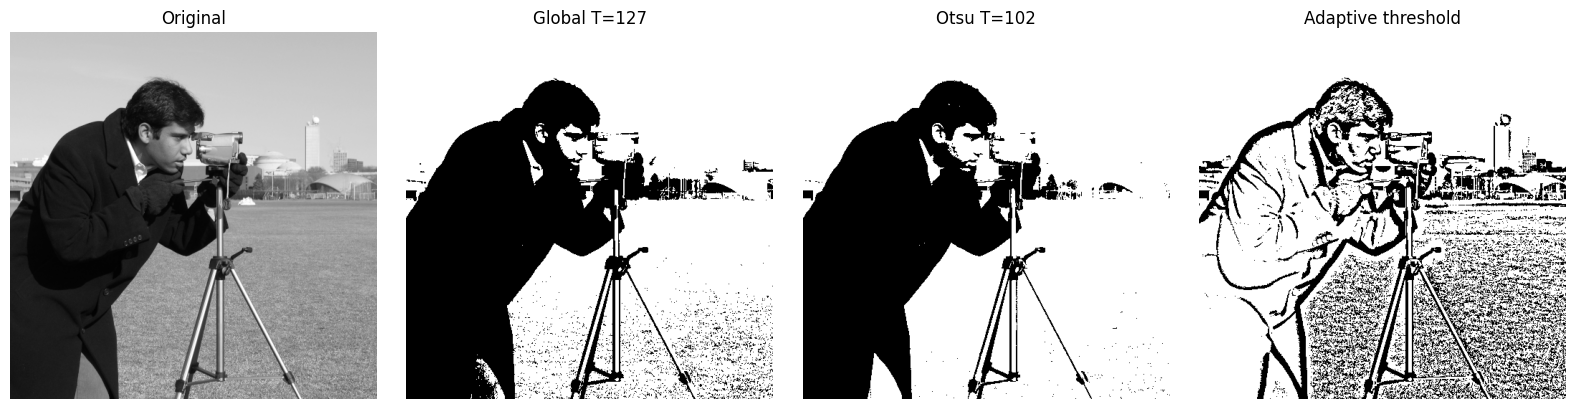

Otsu threshold: 102.0


In [31]:
_, global_t = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
otsu_value, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
adaptive = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 5)
show_images([gray, global_t, otsu, adaptive],
            ["Original", "Global T=127", f"Otsu T={otsu_value:.0f}", "Adaptive threshold"], figsize=(16,4))
print("Otsu threshold:", otsu_value)

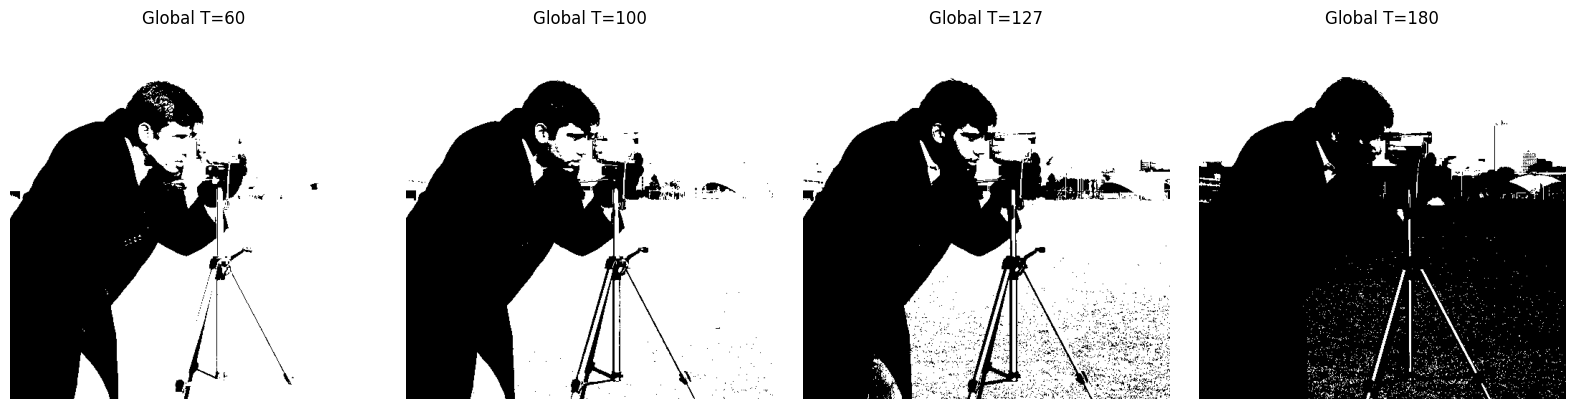

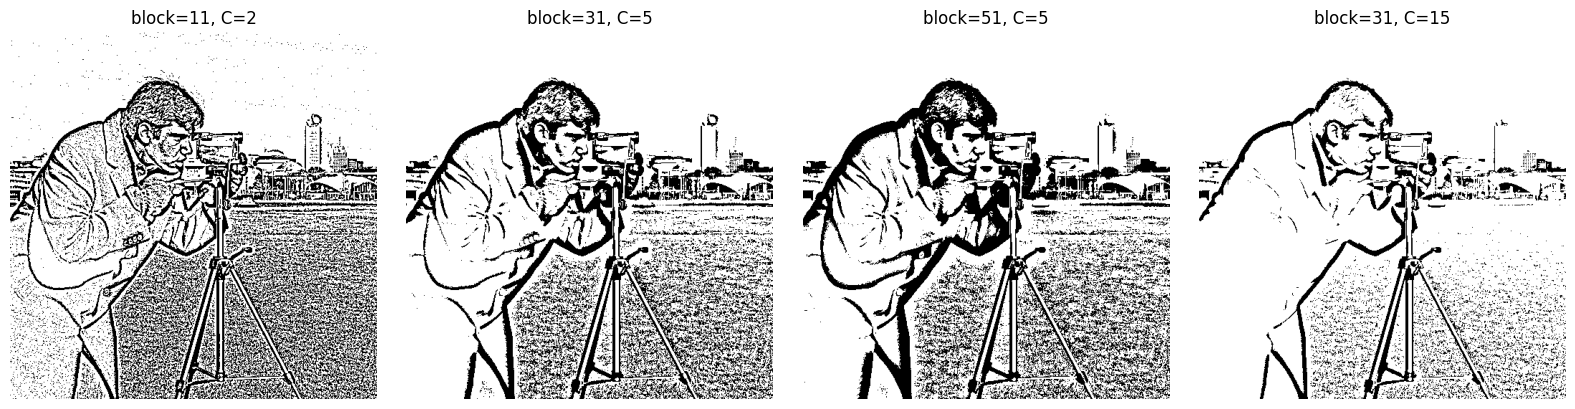

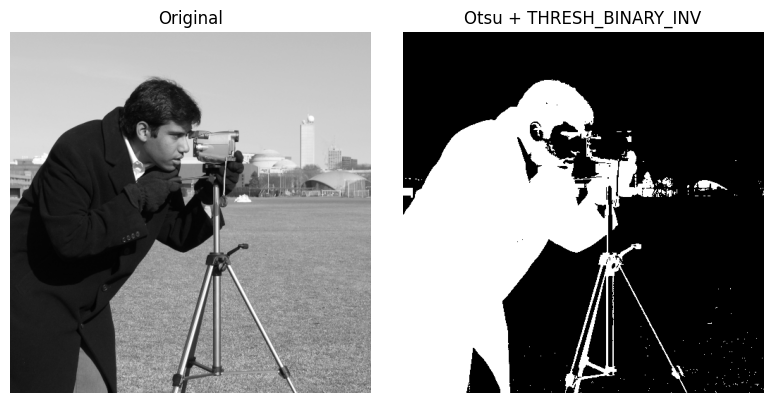

In [32]:
# Several global thresholds
Tg = [60, 100, 127, 180]
show_images([cv2.threshold(gray, t, 255, cv2.THRESH_BINARY)[1] for t in Tg], [f"Global T={t}" for t in Tg], figsize=(16,4))

# Adaptive: vary block size and C
combos = [(11,2), (31,5), (51,5), (31,15)]
show_images([cv2.adaptiveThreshold(gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,b,c) for b,c in combos],
            [f"block={b}, C={c}" for b,c in combos], figsize=(16,4))

# THRESH_BINARY_INV when object is darker than background
_, inv = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
show_images([gray, inv], ["Original", "Otsu + THRESH_BINARY_INV"], figsize=(8,4))

---
# Lab Tasks

## Lab Task 1 — Synthetic image: point, lines and step edge
Create a synthetic image with a bright point, horizontal/vertical/diagonal lines, and a step edge. Test the corresponding detectors.

Strongest point-response location (row, col): (np.int64(30), np.int64(30))


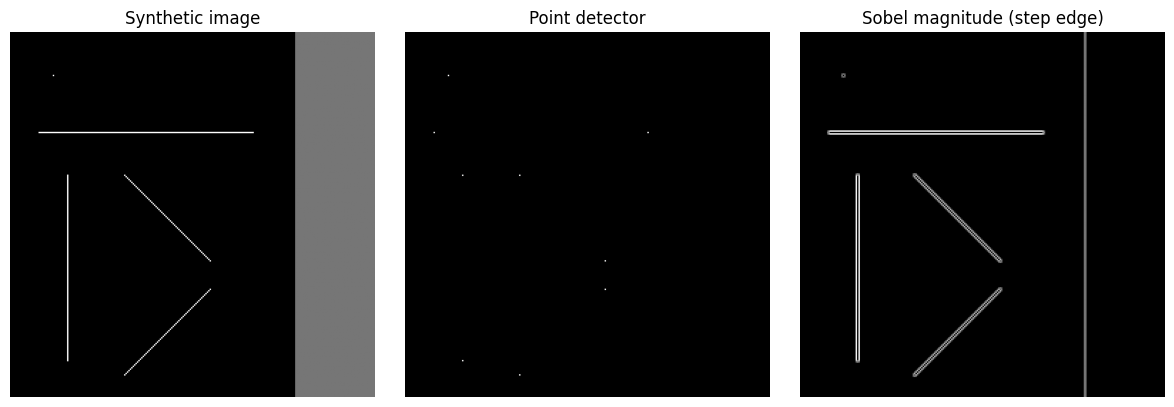

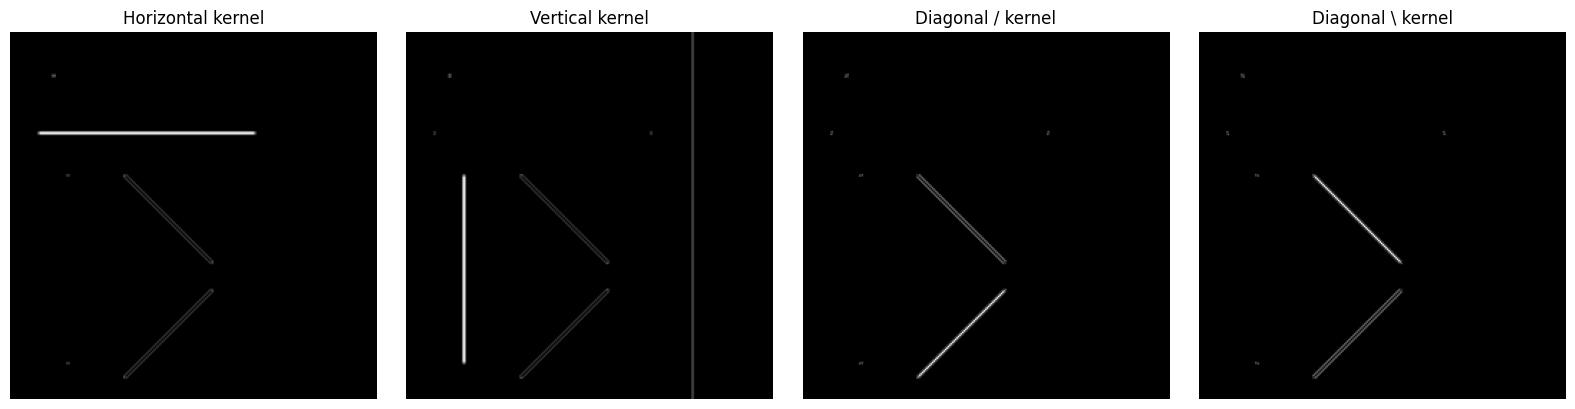

Line in image         Horizontal      Vertical    Diagonal /    Diagonal \
Horizontal line             1170             0             0             0
Vertical line                  0          1170             0             0
Diagonal \ line              390           390           390          1170
Diagonal / line              390           390          1170           390


In [33]:
# --- Build the synthetic image ---
H = W = 256
syn = np.full((H, W), 60, np.uint8)
syn[:, 200:] = 150                                   # step edge at x = 200 (vertical)
syn[30, 30] = 255                                    # bright isolated point
cv2.line(syn, (20, 70),  (170, 70),  255, 1)         # horizontal line
cv2.line(syn, (40, 100), (40, 230),  255, 1)         # vertical line
cv2.line(syn, (80, 100), (140, 160), 255, 1)         # diagonal "\"
cv2.line(syn, (80, 240), (140, 180), 255, 1)         # diagonal "/"
synf = syn.astype(np.float32)

# --- Point detection ---
pt_resp = np.abs(cv2.filter2D(synf, cv2.CV_32F, point_kernel))
pt_mask = (pt_resp > 0.8*pt_resp.max()).astype(np.uint8)*255
print("Strongest point-response location (row, col):", np.unravel_index(pt_resp.argmax(), pt_resp.shape))

# --- Directional line detection ---
lresp = {n: np.abs(cv2.filter2D(synf, cv2.CV_32F, k)) for n, k in line_kernels.items()}

# --- Sobel for the step edge ---
sgx = cv2.Sobel(syn, cv2.CV_32F, 1, 0, ksize=3); sgy = cv2.Sobel(syn, cv2.CV_32F, 0, 1, ksize=3)
smag = cv2.normalize(cv2.magnitude(sgx, sgy), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

show_images([syn, pt_mask, smag], ["Synthetic image", "Point detector", "Sobel magnitude (step edge)"], figsize=(12,4))
show_images(list(lresp.values()), [n+" kernel" for n in lresp], figsize=(16,4))

# --- Strongest response of each kernel inside each line's region ---
rois = {"Horizontal line": (slice(66,75), slice(30,160)),
        "Vertical line":   (slice(110,225), slice(36,45)),
        "Diagonal \\ line": (slice(95,165), slice(75,145)),
        "Diagonal / line":  (slice(175,245), slice(75,145))}
print(f"{'Line in image':18s}" + "".join(f"{k:>14s}" for k in lresp))
for rn, (rs, cs) in rois.items():
    print(f"{rn:18s}" + "".join(f"{lresp[k][rs, cs].max():14.0f}" for k in lresp))

## Lab Task 2 — Noisy step edge: profile and derivatives before/after smoothing

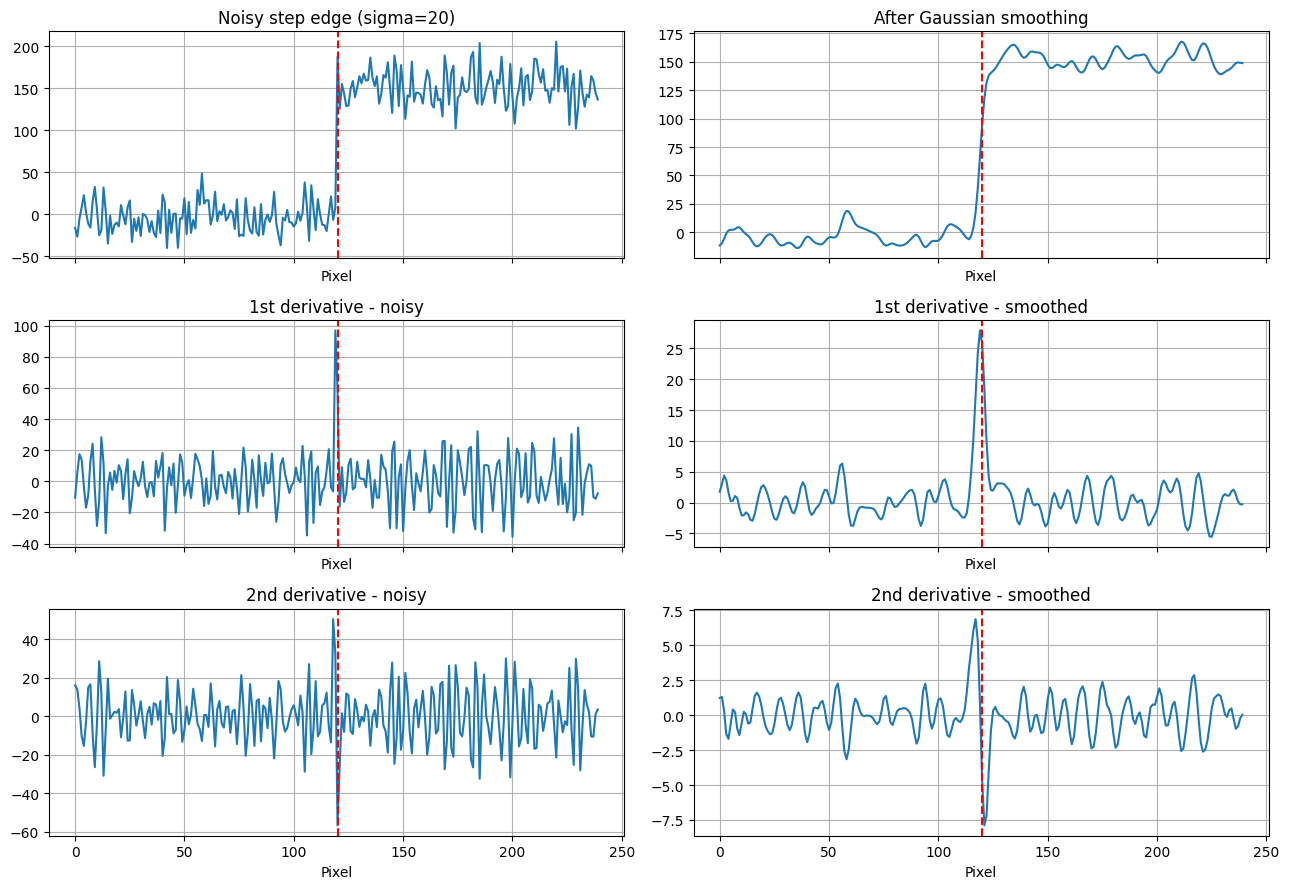

Zero crossings of 2nd derivative  noisy   : 122
Zero crossings of 2nd derivative  smoothed: 56
Peak of |1st derivative| at pixel  noisy: 119  smoothed: 119 (true edge = 120)


In [34]:
rng = np.random.default_rng(5)
sigma_n = 20
prof = np.zeros(240, np.float32); prof[120:] = 150
noisy = prof + rng.normal(0, sigma_n, prof.shape).astype(np.float32)
smooth = cv2.GaussianBlur(noisy.reshape(1,-1), (11,1), 2).ravel()

d1_n = np.gradient(noisy);  d2_n = np.gradient(d1_n)
d1_s = np.gradient(smooth); d2_s = np.gradient(d1_s)

fig, ax = plt.subplots(3, 2, figsize=(13,9), sharex=True)
ax[0,0].plot(noisy);  ax[0,0].set_title(f"Noisy step edge (sigma={sigma_n})")
ax[0,1].plot(smooth); ax[0,1].set_title("After Gaussian smoothing")
ax[1,0].plot(d1_n);   ax[1,0].set_title("1st derivative - noisy")
ax[1,1].plot(d1_s);   ax[1,1].set_title("1st derivative - smoothed")
ax[2,0].plot(d2_n);   ax[2,0].set_title("2nd derivative - noisy")
ax[2,1].plot(d2_s);   ax[2,1].set_title("2nd derivative - smoothed")
for a in ax.ravel():
    a.axvline(120, color="r", ls="--"); a.grid(True); a.set_xlabel("Pixel")
plt.tight_layout(); plt.show()

def zero_crossings(x): return int(np.sum(np.sign(x[:-1]) * np.sign(x[1:]) < 0))
print("Zero crossings of 2nd derivative  noisy   :", zero_crossings(d2_n))
print("Zero crossings of 2nd derivative  smoothed:", zero_crossings(d2_s))
print("Peak of |1st derivative| at pixel  noisy:", int(np.abs(d1_n).argmax()), " smoothed:", int(np.abs(d1_s).argmax()), "(true edge = 120)")

## Lab Task 3 — Canny with three threshold pairs

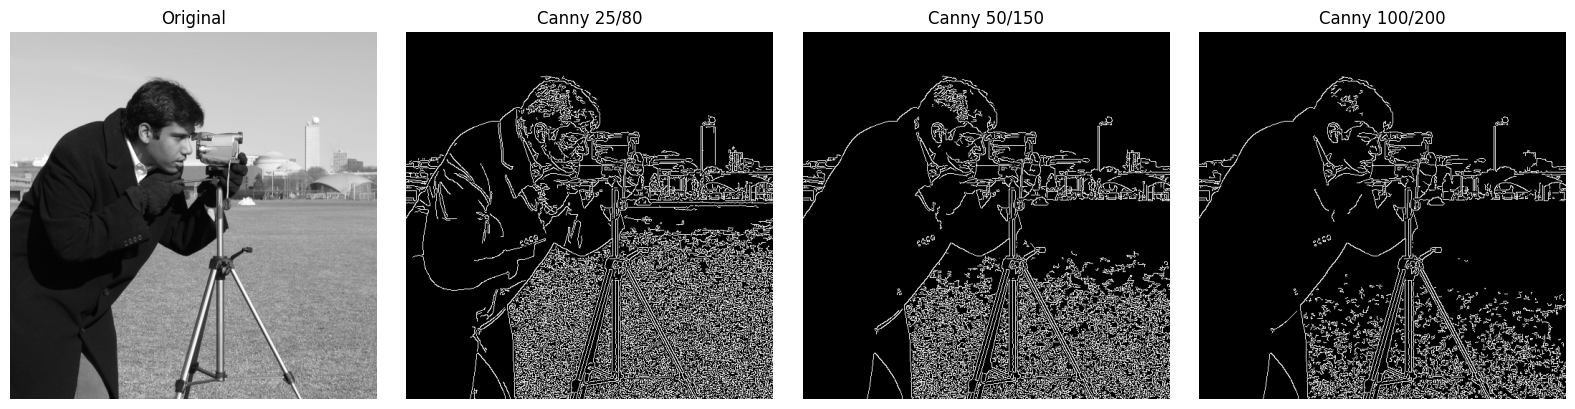

      Pair  Edge pixels  Components  Avg px/component
  25/80           42613        1436              29.7
  50/150          30980         776              39.9
 100/200          19686         743              26.5


In [35]:
pairs = [(25, 80), (50, 150), (100, 200)]
results = [cv2.Canny(gray, lo, hi) for lo, hi in pairs]
show_images([gray] + results, ["Original"] + [f"Canny {lo}/{hi}" for lo, hi in pairs], figsize=(16,4))

n_labels = lambda e: cv2.connectedComponents(e)[0] - 1
print(f"{'Pair':>10s} {'Edge pixels':>12s} {'Components':>11s} {'Avg px/component':>17s}")
for (lo, hi), e in zip(pairs, results):
    nc = n_labels(e)
    print(f"{lo:>4d}/{hi:<5d} {int((e>0).sum()):12d} {nc:11d} {(e>0).sum()/max(nc,1):17.1f}")

## Lab Task 4 — HoughLinesP on a line-containing image

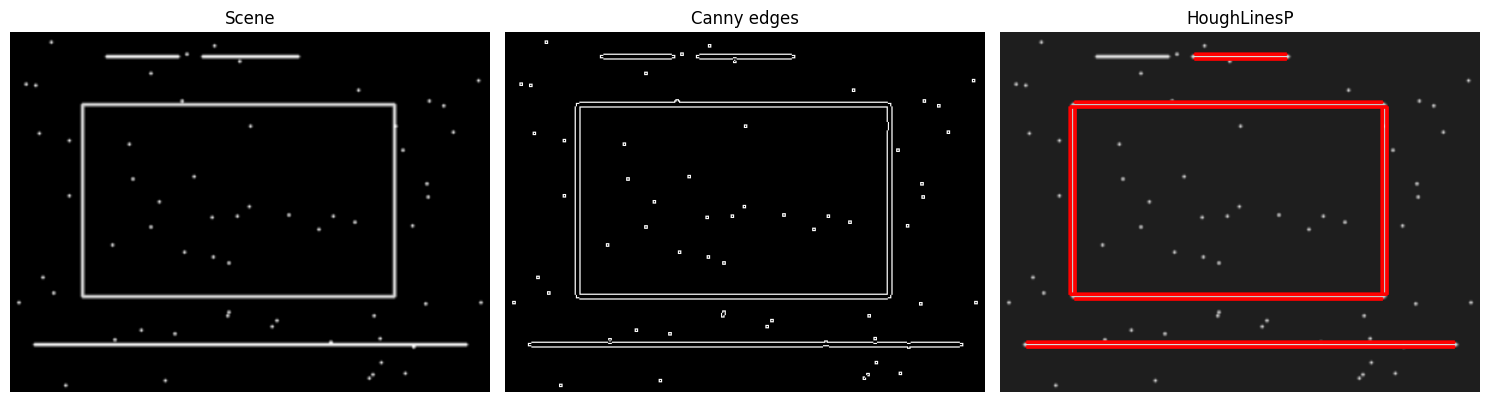

Parameters: rho=1, theta=pi/180, threshold=60, minLineLength=50, maxLineGap=10
Detected segments: 12
Camera image segments (th=80, minLen=50, gap=10): 282


In [38]:
# Line-containing image: structured synthetic scene (clear lines + one gap + clutter) so results can be checked
scene = np.full((300,400), 30, np.uint8)
cv2.rectangle(scene, (60,60), (320,220), 200, 2)                 # rectangle -> 4 lines
cv2.line(scene, (20,260), (380,260), 220, 2)                     # long horizontal line
cv2.line(scene, (80,20), (140,20), 220, 2); cv2.line(scene, (160,20), (240,20), 220, 2)   # line with a 20 px gap
rs = np.random.default_rng(1)
for _ in range(60):                                              # clutter / noise dots
    cv2.circle(scene, (int(rs.integers(0,400)), int(rs.integers(0,300))), 1, 255, -1)
scene = cv2.GaussianBlur(scene, (3,3), 0)
sedges = cv2.Canny(scene, 50, 150)

rho, theta, thr, minLen, maxGap = 1, np.pi/180, 60, 50, 10
L = cv2.HoughLinesP(sedges, rho, theta, thr, minLineLength=minLen, maxLineGap=maxGap)
ov = cv2.cvtColor(scene, cv2.COLOR_GRAY2RGB)
for it in (L if L is not None else []):
    x1, y1, x2, y2 = it.ravel()
    cv2.line(ov, (x1, y1), (x2, y2), (255, 0, 0), 2)
show_images([scene, sedges, ov], ["Scene", "Canny edges", "HoughLinesP"], cmaps=["gray","gray",None], figsize=(15,4))
print(f"Parameters: rho={rho}, theta=pi/180, threshold={thr}, minLineLength={minLen}, maxLineGap={maxGap}")
print("Detected segments:", 0 if L is None else len(L))

# Same method on the real image (camera)
L2 = cv2.HoughLinesP(cv2.Canny(gray,50,150), 1, np.pi/180, 80, minLineLength=50, maxLineGap=10)
print("Camera image segments (th=80, minLen=50, gap=10):", 0 if L2 is None else len(L2))

## Lab Task 5 — Global vs Otsu vs Adaptive thresholding under uneven illumination

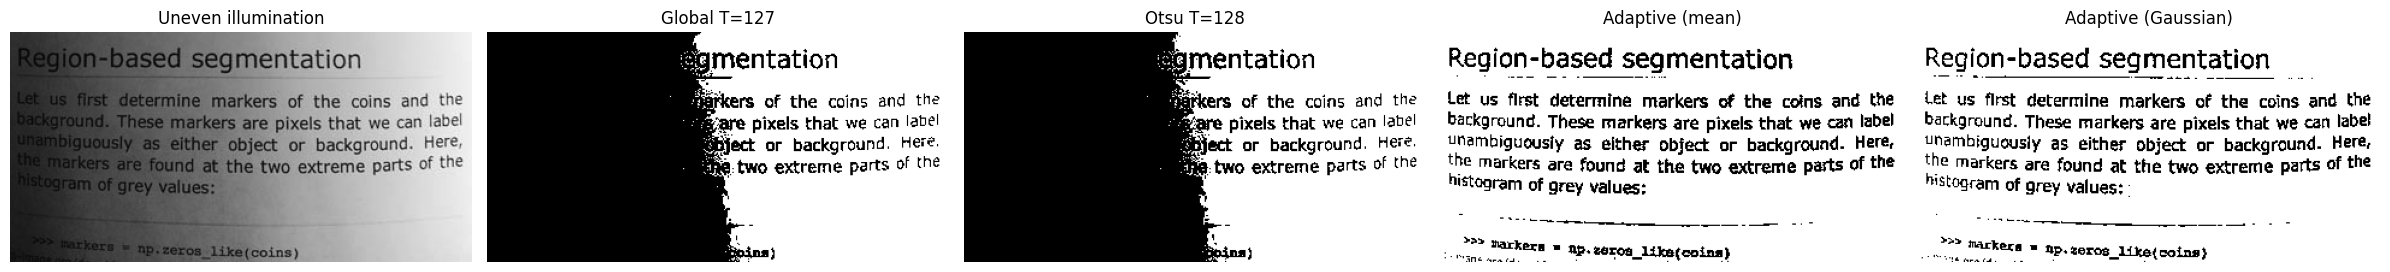

Global 127         IoU with true text mask: 0.400
Otsu               IoU with true text mask: 0.398
Adaptive mean      IoU with true text mask: 0.445
Adaptive Gaussian  IoU with true text mask: 0.439


In [39]:
# Image with uneven illumination: dark text on paper, multiplied by a smooth lighting gradient
try:
    base = img_as_ubyte(data.page())
except Exception:
    base = np.full((250,400), 200, np.uint8)
    for i in range(8):
        cv2.putText(base, "Segmentation lab text", (10, 30+30*i), cv2.FONT_HERSHEY_SIMPLEX, 0.9, 40, 2)

h, w = base.shape
xx = np.tile(np.linspace(0.35, 1.0, w, dtype=np.float32), (h,1))          # left side is darker
uneven = np.clip(base.astype(np.float32) * xx, 0, 255).astype(np.uint8)

_, g127 = cv2.threshold(uneven, 127, 255, cv2.THRESH_BINARY)
ot_val, ot = cv2.threshold(uneven, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
ad_m = cv2.adaptiveThreshold(uneven, 255, cv2.ADAPTIVE_THRESH_MEAN_C,     cv2.THRESH_BINARY, 35, 10)
ad_g = cv2.adaptiveThreshold(uneven, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 35, 10)

show_images([uneven, g127, ot, ad_m, ad_g],
            ["Uneven illumination", "Global T=127", f"Otsu T={ot_val:.0f}", "Adaptive (mean)", "Adaptive (Gaussian)"],
            figsize=(24,5))

# Quantitative check: fraction of 'foreground' (text) pixels in left vs right half of each result
ref = (base < 128)                      # ground-truth text mask from the evenly lit image
def score(binary):
    pred = binary == 0                  # text is black (0) in the binary output
    inter = np.logical_and(pred, ref).sum(); union = np.logical_or(pred, ref).sum()
    return inter/union
for n, b in [("Global 127", g127), ("Otsu", ot), ("Adaptive mean", ad_m), ("Adaptive Gaussian", ad_g)]:
    print(f"{n:18s} IoU with true text mask: {score(b):.3f}")